# Experiment 3: PolicyBench Validation（实验三：PolicyBench验证）

## 1. Install Packages（安装依赖）

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys

packages = {"pandas": "pandas", "numpy": "numpy", "huggingface_hub": "huggingface-hub",
            "rank_bm25": "rank-bm25", "sentence_transformers": "sentence-transformers",
            "matplotlib": "matplotlib"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Python:", sys.executable)


Python: C:\Users\lenovo\anaconda3\envs\torch_env\python.exe


In [2]:
import json
import pandas as pd
from IPython.display import display

PROJECT = Path.cwd()
if not (PROJECT / "policybench_validation.py").exists():
    PROJECT = Path(r"C:\Users\lenovo\Desktop\888\project")
if not (PROJECT / "policybench_validation.py").exists():
    raise FileNotFoundError("请在包含 policybench_validation.py 的 project 文件夹中运行。")
sys.path.insert(0, str(PROJECT))

import policybench_validation as pb
import rag_pipeline as rag
rag.RUN_LABEL = ""

MODE = "formal"
RUN_LABEL = "v3"
RUN_GENERATION = False
print("项目目录:", PROJECT)
print("模式:", MODE, "生成开关:", RUN_GENERATION)

项目目录: C:\Users\lenovo\Desktop\888\project
模式: formal 生成开关: False


## 2. Data Acquisition and Deduplication（数据获取与去重）

In [3]:
raw, source_manifest = pb.acquire()
print("原始行列数:", raw.shape)
print("字段:", raw.columns.tolist())
print("独立 identifier:", raw.identifier.nunique())
display(raw[["identifier", "knowledge_base_identifier", "question", "expected_answer"]].head())
display(pd.Series(source_manifest))


原始行列数: (3310, 7)
字段: ['path_to_store', 'knowledge_base_identifier', 'creation_timestamp', 'question', 'expected_answer', 'identifier', 'context_questions']
独立 identifier: 331


,identifier,knowledge_base_identifier,question,expected_answer
0,ICA_0,ICA_134,If a traveller plans to visit Malaysia with th...,It is important that those travelling in a gro...
1,ICA_1,ICA_134,What is a Foreign Identification Number (FIN) ...,A Foreign Identification Number (FIN) is a uni...
2,ICA_2,ICA_134,How can I check the application status of my R...,You can enquire the details of your REP by cli...
3,ICA_3,ICA_134,Do I need to translate my documents that are n...,You will need to provide original documents an...
4,ICA_4,ICA_134,What is the difference between a Dependant's P...,Dependant's Pass (DP) is issued to dependants ...


repo                                          govtech/PolicyBenchFull
revision                     481861001a3d6a403575261202b64e01f2fc753f
retrieved_at_utc                     2026-10-23T15:14:42.470337+00:00
dataset_url         https://huggingface.co/datasets/govtech/Policy...
license             No explicit dataset license found at initial i...
sha256              021437f730d1cb2b4e5bb76d626bfa0091df98359b745f...
dtype: str

In [4]:
corpus, queries, domain_counts = pb.prepare_data(raw)
print("去重后的问题:", len(queries), "唯一答案文档:", len(corpus))
display(domain_counts)
display(queries.head())
assert corpus.doc_id.is_unique and queries.query_id.is_unique
assert queries.doc_id.isin(corpus.doc_id).all()
print("数据目录:", pb.DATA)


去重后的问题: 331 唯一答案文档: 331


,query_type,unique_queries
0,BTT,55
1,CPF_111,112
2,ICA_134,135
3,medishield,29


,query_id,doc_id,query_type,query,reference_answer
0,BTT_0,PB_9c27ce47f88ef02aeefc,BTT,What is the impact of leaving a vehicle engine...,"It is an offence, and offenders are liable to ..."
1,BTT_1,PB_57b4cb852a1cc98f4ad5,BTT,What does a broken white line indicate on a tw...,It indicates the centre line of a two-way road.
2,BTT_10,PB_4a5e366a1e27905d0545,BTT,What gear practice should be followed while dr...,Avoid dragging the engine by using the correct...
3,BTT_11,PB_50b7e744316cb05299f8,BTT,What does the acronym 'SH' stand for in Singap...,Shoulder
4,BTT_12,PB_1bd233e28127cfee0c86,BTT,What should drivers do if the traffic lights t...,Drivers should proceed to complete their turn ...


数据目录: C:\Users\lenovo\Desktop\888\project\policybench_data


## 3. Source Audit Criteria（来源审核标准）

- source_url：指向支持该条答案的具体来源页面或文档。
- evidence_quote：与参考答案相对应的原文证据。
- answer_supported：根据实际证据判断是否支持；无证据时不得标记为支持。
- reviewed_by_researcher：研究者亲自核对后填写。

In [5]:
audit = pd.read_csv(pb.DATA / "source_quality_audit.csv", keep_default_na=False)
print("已标记 researcher review:", audit.reviewed_by_researcher.ne("").sum(), "/", len(audit))
display(audit.head(3))


已标记 researcher review: 0 / 331


,query_id,doc_id,query_type,query,reference_answer,source_url,source_snapshot,evidence_quote,answer_supported,reviewed_by_researcher,review_notes
0,BTT_0,PB_9c27ce47f88ef02aeefc,BTT,What is the impact of leaving a vehicle engine...,"It is an offence, and offenders are liable to ...",,,,,,
1,BTT_1,PB_57b4cb852a1cc98f4ad5,BTT,What does a broken white line indicate on a tw...,It indicates the centre line of a two-way road.,,,,,,
2,BTT_10,PB_4a5e366a1e27905d0545,BTT,What gear practice should be followed while dr...,Avoid dragging the engine by using the correct...,,,,,,


## 4. BM25, Dense and RRF Retrieval（BM25、稠密与RRF检索）

In [6]:
rankings, retrieval_manifest = pb.retrieve(corpus, queries)
display(pd.Series(retrieval_manifest))
length_audit = pd.read_csv(pb.DATA / "dense_token_audit.csv")
display(length_audit.groupby("kind").agg(n=("id", "size"), max_tokens=("tokens", "max"),
                                       truncated=("truncated", "sum")))


Reusing original experiment under documented reporting/parser maintenance compatibility.


protocol                           policybench-faq-answer-corpus-v1
corpus_sha256     22282714b3c289fd4c5a326e281213e239450012d97b60...
queries_sha256    86f1c4c81744c17e9d7a763f87f004240ada1ce0446c8c...
dense_model                                  BAAI/bge-small-en-v1.5
dense_revision             5c38ec7c405ec4b44b94cc5a9bb96e735b38267a
instruction       Represent this sentence for searching relevant...
bm25_k1                                                         1.5
bm25_b                                                         0.75
rrf_k                                                            60
code_sha256       287840f7b64e63c5a13a34bf5cb01c5de2ed623d0d3600...
versions          {'numpy': '2.4.4', 'pandas': '3.0.3', 'rank-bm...
dtype: object

,n,max_tokens,truncated
kind,,,
document,331,816,2
query,331,60,0


## 5. Retrieval Evaluation Criteria（检索评价标准）

- Recall@k = 前 k 位相关文档数 / 全部相关文档数；Hit@5 = 前五位是否至少命中一个相关文档。
- MRR = 首个相关文档排名倒数的平均值；nDCG@5 按相关文档排名折损计算。
- 95%置信区间以 FAQ 为单位进行 2,000 次配对 bootstrap。

In [7]:
retrieval_ci, retrieval_differences = pb.retrieval_report(corpus, queries, rankings)
overall = retrieval_ci[retrieval_ci.query_type == "overall"]
display(overall.pivot(index="method", columns="metric", values="estimate").round(4))
display(overall[["method", "metric", "estimate", "ci_low", "ci_high", "n_groups"]])
display(retrieval_differences[retrieval_differences.query_type == "overall"])


metric,Hit@5,MRR,Recall@1,Recall@10,Recall@5,nDCG@5
method,,,,,,
bm25,0.8187,0.7454,0.6798,0.8671,0.8187,0.7565
dense,0.8671,0.8072,0.7583,0.9094,0.8671,0.8158
hybrid,0.8640,0.7897,0.7341,0.8912,0.8640,0.8030


,method,metric,estimate,ci_low,ci_high,n_groups
0,bm25,Recall@1,0.679758,0.628399,0.728097,331
1,dense,Recall@1,0.758308,0.709970,0.803625,331
2,hybrid,Recall@1,0.734139,0.685801,0.779456,331
3,bm25,Recall@5,0.818731,0.776435,0.858006,331
4,dense,Recall@5,0.867069,0.830816,0.903323,331
5,hybrid,Recall@5,0.864048,0.824773,0.900378,331
6,bm25,Recall@10,0.867069,0.830816,0.903323,331
7,dense,Recall@10,0.909366,0.879154,0.939577,331
8,hybrid,Recall@10,0.891239,0.854985,0.924471,331
9,bm25,Hit@5,0.818731,0.776435,0.858006,331


,query_type,metric,contrast,difference,ci_low,ci_high,n_groups
0,overall,Recall@1,dense - bm25,0.078550,0.036254,0.120846,331
1,overall,Recall@1,hybrid - bm25,0.054381,0.018127,0.087613,331
2,overall,Recall@1,hybrid - dense,-0.024169,-0.057402,0.006042,331
3,overall,Recall@5,dense - bm25,0.048338,0.015106,0.084592,331
4,overall,Recall@5,hybrid - bm25,0.045317,0.021148,0.072508,331
5,overall,Recall@5,hybrid - dense,-0.003021,-0.027190,0.018127,331
6,overall,Recall@10,dense - bm25,0.042296,0.015106,0.069486,331
7,overall,Recall@10,hybrid - bm25,0.024169,0.003021,0.048338,331
8,overall,Recall@10,hybrid - dense,-0.018127,-0.036254,0.000000,331
9,overall,Hit@5,dense - bm25,0.048338,0.015106,0.084592,331


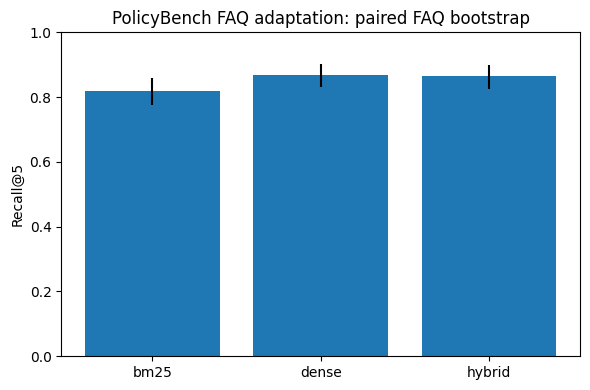

In [8]:
import matplotlib.pyplot as plt

chart = overall[overall.metric == "Recall@5"].set_index("method")
figure, axis = plt.subplots(figsize=(6, 4))
axis.bar(chart.index, chart.estimate)
axis.vlines(range(len(chart)), chart.ci_low, chart.ci_high, color="black")
axis.set_ylim(0, 1)
axis.set_ylabel("Recall@5")
axis.set_title("PolicyBench FAQ adaptation: paired FAQ bootstrap")
figure.tight_layout()
figure.savefig(pb.DATA / "retrieval_comparison.png", dpi=180)
plt.show()


## 6. Four-System Experiment Setup（四系统实验准备）

In [9]:
sample, output_dir, run_manifest, mode_key = pb.prepare_run(corpus, queries, MODE, RUN_LABEL)
print("本次问题数:", len(sample), "预期回答数:", len(sample) * 4)
print("结果目录:", output_dir)
display(sample.groupby("query_type").size().rename("n_queries"))
display(sample[["query_id", "query_type", "query"]].head())


Reusing original experiment under documented reporting/parser maintenance compatibility.
本次问题数: 327 预期回答数: 1308
结果目录: C:\Users\lenovo\Desktop\888\project\rag_policybench_formal_v3


query_type
BTT            54
CPF_111       111
ICA_134       134
medishield     28
Name: n_queries, dtype: int64

,query_id,query_type,query
0,BTT_0,BTT,What is the impact of leaving a vehicle engine...
1,BTT_1,BTT,What does a broken white line indicate on a tw...
2,BTT_10,BTT,What gear practice should be followed while dr...
3,BTT_11,BTT,What does the acronym 'SH' stand for in Singap...
4,BTT_12,BTT,What should drivers do if the traffic lights t...


## 7. Answer Generation（回答生成）

In [10]:
if RUN_GENERATION:
    generated = pb.generate(corpus, sample, rankings, output_dir, run_manifest)
else:
    generated = rag.export_answers(output_dir)
assert len(generated) == len(sample) * 4, 'Enable RUN_GENERATION for missing answers.'
display(generated[['query_id', 'system', 'answer', 'seconds', 'hit_token_limit']].head())

,query_id,system,answer,seconds,hit_token_limit
0,BTT_0,BM25-RAG,Leaving a vehicle engine running idling increa...,9.288126,False
1,BTT_0,Dense-RAG,Leaving a vehicle's engine running idly is pro...,11.490770,False
2,BTT_0,No-RAG,The Environmental Protection and Management (V...,6.668734,False
3,BTT_0,RRF-RAG,Leaving a vehicle engine running idly impacts ...,10.063166,False
4,BTT_10,BM25-RAG,"While driving a manual vehicle, use the correc...",6.405276,False


## 8. Automatic Evaluation Criteria（自动评价标准）

- Correctness：0 = 错误或无实质回答；1 = 部分正确但有重要遗漏；2 = 正确且覆盖参考答案主要事实。
- Relevance：0 = 未回答问题；1 = 部分回答；2 = 直接回答问题。
- Faithfulness：0 = 主要事实无证据支持或与证据矛盾；1 = 部分事实有支持；2 = 所有实质事实均有支持。无上下文或无事实主张的纯拒答为 N/A。

In [11]:
print('Recovered JSON:', rag.recover_saved_judgments(output_dir))
if RUN_GENERATION:
    rag.judge(mode_key)
assert len(list((output_dir / 'judgments').glob('*.json'))) == len(sample) * 4
summary = pb.report(mode_key)
display(summary)
display(pd.read_csv(output_dir / 'judge_coverage.csv'))
display(pd.read_csv(output_dir / 'answer_paired_differences_ci.csv').head(12))

Recovered JSON: 0


Main comparison: paired complete-FAQ means and matching 95% CIs. All-available descriptive means are saved separately.


,correctness,correctness_ci_low,correctness_ci_high,n_faq_groups_correctness,relevance,relevance_ci_low,relevance_ci_high,n_faq_groups_relevance,faithfulness,faithfulness_ci_low,faithfulness_ci_high,n_faq_groups_faithfulness,reference_token_f1_proxy,reference_token_f1_proxy_ci_low,reference_token_f1_proxy_ci_high,n_faq_groups_reference_token_f1_proxy
system,,,,,,,,,,,,,,,,
No-RAG,1.076453,1.003058,1.149847,327,1.103976,1.039679,1.171254,327,NaN,NaN,NaN,0,0.267127,0.252831,0.281174,327
BM25-RAG,1.883792,1.837920,1.923547,327,1.886850,1.840979,1.926606,327,1.957792,1.925325,1.983766,308,0.425776,0.401883,0.448988,327
Dense-RAG,1.941896,1.911315,1.969419,327,1.941896,1.914373,1.966361,327,1.990260,1.977273,2.000000,308,0.420324,0.398097,0.443070,327
RRF-RAG,1.926606,1.889908,1.957187,327,1.935780,1.902141,1.966361,327,1.980519,1.961039,1.996753,308,0.420847,0.397673,0.442586,327


,system,judge_status,count
0,BM25-RAG,ok,327
1,Dense-RAG,ok,327
2,No-RAG,ok,327
3,RRF-RAG,ok,327


,query_type,metric,contrast,difference,ci_low,ci_high,n_groups
0,overall,correctness,Dense-RAG - BM25-RAG,0.058104,0.027523,0.088685,327
1,overall,correctness,No-RAG - BM25-RAG,-0.807339,-0.889908,-0.721713,327
2,overall,correctness,RRF-RAG - BM25-RAG,0.042813,0.012232,0.076453,327
3,overall,correctness,No-RAG - Dense-RAG,-0.865443,-0.944954,-0.785933,327
4,overall,correctness,RRF-RAG - Dense-RAG,-0.015291,-0.045872,0.015291,327
5,overall,correctness,RRF-RAG - No-RAG,0.850153,0.770642,0.926606,327
6,BTT,correctness,Dense-RAG - BM25-RAG,0.203704,0.055556,0.351852,54
7,BTT,correctness,No-RAG - BM25-RAG,-0.296296,-0.518519,-0.074074,54
8,BTT,correctness,RRF-RAG - BM25-RAG,0.222222,0.074074,0.388889,54
9,BTT,correctness,No-RAG - Dense-RAG,-0.500000,-0.703704,-0.277778,54


## 9. Human Review and Calibration（人工复核与校准）

In [12]:
review_path = output_dir / "human_review_blinded.csv"
if review_path.exists():
    calibration = rag.import_human_review(mode_key)
    display(calibration)
    print("有效配对为 0 表示尚无可比较的人工评分。")
else:
    print("完成生成、评分和报告后，人工复核表才会创建。")


,metric,n_paired_reviews,exact_agreement,mean_absolute_difference
0,correctness,80,0.612500,0.462500
1,relevance,80,0.837500,0.175000
2,faithfulness,56,0.678571,0.357143


有效配对为 0 表示尚无可比较的人工评分。
